# Passo 3 – Variáveis (Fase A: RF ingênua, só acerto)

**Fase A:** nenhuma escolha usa custo ou dinheiro. O critério é o **R² fora da amostra** (validação 2024):
$$R^2 = 1 - \frac{\text{erro quadrático do modelo}}{\text{erro quadrático de prever zero}}\qquad\text{Theil } U = \sqrt{1-R^2}$$

**Como foi feito:** RF fixa e moderada (300 árvores, profundidade 6, folha 0,5%, 50% das variáveis), treinada uma vez em 10/2020–12/2023, prevendo 2024. Todos os candles: **1, 5, 15, 30 e 60 min**.

**Regras de escolha (definidas antes de rodar):**
1. Nº de lags (3, 5 ou 10): o de **maior R² médio entre os 5 candles**.
2. Grupos (somados um a um aos lags): o conjunto de **maior R² médio entre os 5 candles**.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
import rf_zero as rz
win_1m = rz.carregar("../../dados/WINN_M1/WIN$N_M1.csv")
CANDLES = [1, 5, 15, 30, 60]
dados = {}
for m in CANDLES:
    b, grupos = rz.criar_variaveis(rz.adicionar_alvo(rz.reamostrar(win_1m, m)), 10)
    todas = sum(grupos.values(), [])
    b = b.dropna(subset=todas + ["ret_prox"])
    dados[m] = (b[b.index < rz.VALIDACAO[0]], rz.periodo(b, rz.VALIDACAO), grupos)
def rodar(m, cols):
    tr, va, _ = dados[m]
    rf = rz.rf_padrao(len(tr)).fit(tr[cols], tr["ret_prox"])
    return rf, rf.predict(va[cols])
{m: (len(d[0]), len(d[1])) for m, d in dados.items()}

{1: (364303, 135029),
 5: (72255, 26808),
 15: (23692, 8769),
 30: (11451, 4259),
 60: (5336, 2004)}

## 3.1 Quantos lags?

In [2]:
t0 = time.time(); res = {}
for m in CANDLES:
    va = dados[m][1]
    for k in [3, 5, 10]:
        _, p = rodar(m, [f"ret_lag{i}" for i in range(1, k + 1)])
        res[(f"{m} min", k)] = rz.resumo_acerto(va.assign(prev=p))
tab_lags = pd.DataFrame(res).T; tab_lags.index.names = ["candle", "lags"]
print(f"{time.time() - t0:.0f} s")
r2_lags = tab_lags["R² %"].unstack("lags")
r2_lags.loc["média"] = r2_lags.mean()
N_LAGS = int(r2_lags.loc["média"].idxmax())
print("Escolha pela regra 1 →", N_LAGS, "lags")
r2_lags.round(3)

153 s
Escolha pela regra 1 → 10 lags


lags,3,5,10
candle,,,
1 min,-0.044,-0.042,-0.054
15 min,-0.251,-0.142,-0.086
30 min,-0.162,-0.166,-0.170
5 min,0.011,0.013,0.004
60 min,-0.392,-0.202,-0.170
média,-0.168,-0.108,-0.095


## 3.2 Somando os grupos um a um

In [3]:
ordem = ["lags", "forma", "volatilidade", "volume", "contexto_dia"]
res = {}; t0 = time.time()
for m in CANDLES:
    tr, va, g = dados[m]; cols = []
    for grp in ordem:
        cols = cols + ([f"ret_lag{i}" for i in range(1, N_LAGS + 1)] if grp == "lags" else g[grp])
        _, p = rodar(m, cols)
        res[(f"{m} min", "+ " + grp)] = rz.resumo_acerto(va.assign(prev=p))
tab_grupos = pd.DataFrame(res).T; tab_grupos.index.names = ["candle", "conjunto"]
print(f"{time.time() - t0:.0f} s")
r2_grupos = tab_grupos["R² %"].unstack("candle")[[f"{m} min" for m in CANDLES]].loc[["+ " + o for o in ordem]]
r2_grupos["média"] = r2_grupos.mean(axis=1)
ESCOLHA = r2_grupos["média"].idxmax()
print("Escolha pela regra 2 →", ESCOLHA)
r2_grupos.round(3)

632 s
Escolha pela regra 2 → + contexto_dia


candle,1 min,5 min,15 min,30 min,60 min,média
conjunto,,,,,,
+ lags,-0.054,0.004,-0.086,-0.170,-0.170,-0.095
+ forma,-0.061,0.002,-0.067,-0.282,0.269,-0.028
+ volatilidade,-0.063,-0.010,-0.036,-0.194,-0.025,-0.066
+ volume,-0.066,-0.012,-0.005,-0.107,0.304,0.023
+ contexto_dia,-0.058,-0.018,0.002,-0.108,0.437,0.051


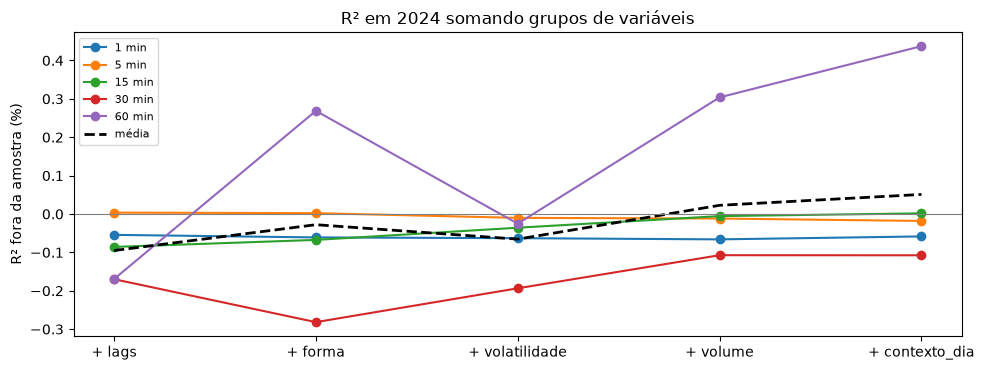

In [4]:
tab_lags.to_csv("saidas/A3_lags.csv"); tab_grupos.to_csv("saidas/A3_grupos.csv")
fig, ax = plt.subplots(figsize=(10, 3.8))
for m in CANDLES:
    ax.plot(range(len(ordem)), r2_grupos[f"{m} min"], "o-", label=f"{m} min")
ax.plot(range(len(ordem)), r2_grupos["média"], "k--", lw=2, label="média")
ax.set_xticks(range(len(ordem))); ax.set_xticklabels(["+ " + o for o in ordem]); ax.axhline(0, color="gray", lw=.8)
ax.set_ylabel("R² fora da amostra (%)"); ax.set_title("R² em 2024 somando grupos de variáveis"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("passo03_grupos.png", dpi=120); plt.show()

## 3.3 Importância por permutação (conjunto escolhido)

Quanto o R² cai ao embaralhar cada grupo na validação.

In [5]:
rng = np.random.default_rng(0); imp = {}
idx_fim = ordem.index(ESCOLHA.replace("+ ", ""))
for m in CANDLES:
    tr, va, g = dados[m]
    grupos_usados = {"lags": [f"ret_lag{i}" for i in range(1, N_LAGS + 1)]} | {k: g[k] for k in ordem[1:idx_fim + 1]}
    cols = sum(grupos_usados.values(), [])
    rf, p = rodar(m, cols)
    y = va["ret_prox"].values; base = rz.r2_oos(p, y); linha = {}
    for nome, gc in grupos_usados.items():
        quedas = []
        for _ in range(3):
            X = va[cols].copy(); X[gc] = X[gc].values[rng.permutation(len(X))]
            quedas.append(base - rz.r2_oos(rf.predict(X), y))
        linha[nome] = np.mean(quedas)
    imp[f"{m} min"] = linha
tab_imp = pd.DataFrame(imp); tab_imp.to_csv("saidas/A3_importancia.csv")
tab_imp.round(3)

,1 min,5 min,15 min,30 min,60 min
lags,-0.014,0.016,0.050,0.212,0.176
forma,-0.021,0.021,-0.023,-0.161,0.028
volatilidade,-0.003,-0.009,0.011,0.147,0.082
volume,-0.001,-0.012,0.043,0.248,0.747
contexto_dia,0.012,0.007,0.022,-0.061,0.106


## Conclusões do Passo 3

1. **Lags: 10** (regra 1). R² médio: −0,168 (3 lags), −0,108 (5), −0,095 (10). Mais passado ajudou em 15 e 60 min; em 1, 5 e 30 min as diferenças são mínimas.
2. **Grupos: todos** (regra 2). Somar forma, volatilidade, volume e contexto do dia levou o R² médio de −0,095 a **+0,051**. É o único conjunto com média positiva.
3. **Quem tem sinal:** só o candle de **60 min** tem R² claramente positivo (+0,44% com o conjunto completo); 15 min chega a ~0; 1, 5 e 30 min ficam negativos (erram mais que prever zero).
4. **Importância (queda do R² ao embaralhar):** no 60 min, o **volume relativo** é de longe o mais importante (0,75 ponto de R²), seguido de lags e contexto do dia. No 1 min nenhum grupo importa (quedas de ~0,01).
5. **Ressalva da regra da média:** o R² médio é puxado pelo 60 min, que tem os maiores valores (positivos e negativos). A escolha seria a mesma olhando só os candles com R² > 0.

➡️ **Decisão:** **10 lags + os 4 grupos = 20 variáveis** para os passos seguintes.
